## HW Calibration

### 1. 시장 데이터 정의 (Spot Curve & Swaption Volatility)

이 단계에서는 분석의 기초가 되는 현재 시장의 금리 커브(Zero Rate)와 시장에서 거래되는 스왑션의 변동성 데이터를 입력합니다.

주요 내용: 3개월부터 30년까지의 만기별 할인계수(DF)와 만기(Expiry) 및 테너(Tenor)별 스왑션 변동성 데이터 정의가 주어집니다.

In [1]:
SPOT_CURVE_DATA = [
    {"term": "3MO", "tenor": 0.25,   "zero_rate": 3.85237, "df": 0.990415},
    {"term": "6MO", "tenor": 0.5,    "zero_rate": 3.81734,  "df": 0.981091},
    {"term": "9MO", "tenor": 0.75,   "zero_rate": 3.84615, "df": 0.971592},
    {"term": "12MO", "tenor": 1.0,    "zero_rate": 3.77519, "df": 0.962948},
    {"term": "18MO", "tenor": 1.5,    "zero_rate": 3.76813, "df": 0.945049},
    {"term": "2YR",  "tenor": 2.0,    "zero_rate": 3.69239, "df": 0.9288},
    {"term": "3YR",  "tenor": 3.0,    "zero_rate": 3.61293, "df": 0.896924},
    {"term": "4YR",  "tenor": 4.0,    "zero_rate": 3.6143,  "df": 0.865136},
    {"term": "5YR",  "tenor": 5.0,    "zero_rate": 3.64661, "df": 0.833076},
    {"term": "6YR",  "tenor": 6.0,    "zero_rate": 3.69318, "df": 0.800919},
    {"term": "7YR",  "tenor": 7.0,    "zero_rate": 3.74242, "df": 0.769219},
    {"term": "8YR",  "tenor": 8.0,    "zero_rate": 3.79198, "df": 0.737874},
    {"term": "9YR",  "tenor": 9.0,    "zero_rate": 3.84128, "df": 0.707342},
    {"term": "10YR", "tenor": 10.0,   "zero_rate": 3.89041, "df": 0.677345},
    {"term": "12YR", "tenor": 12.0,   "zero_rate": 3.99071, "df": 0.619135},
    {"term": "15YR", "tenor": 15.0,   "zero_rate": 4.11705, "df": 0.538895},
    {"term": "20YR", "tenor": 20.0,   "zero_rate": 4.2103,  "df": 0.430424},
    {"term": "25YR", "tenor": 25.0,   "zero_rate": 4.18391, "df": 0.350946},
    {"term": "30YR", "tenor": 30.0,   "zero_rate": 4.09855, "df": 0.292026}
]

SWAPTION_DATA = [
    # --- Expiry: 1Mo (0.0833) ---
    {"expiry": 0.0833, "tenor": 1.0, "vol": 0.3103}, {"expiry": 0.0833, "tenor": 2.0, "vol": 0.3428}, {"expiry": 0.0833, "tenor": 3.0, "vol": 0.3306}, {"expiry": 0.0833, "tenor": 4.0, "vol": 0.3067}, {"expiry": 0.0833, "tenor": 5.0, "vol": 0.2914},
    {"expiry": 0.0833, "tenor": 6.0, "vol": 0.2729}, {"expiry": 0.0833, "tenor": 7.0, "vol": 0.2551}, {"expiry": 0.0833, "tenor": 8.0, "vol": 0.2449}, {"expiry": 0.0833, "tenor": 9.0, "vol": 0.2346}, {"expiry": 0.0833, "tenor": 10.0, "vol": 0.2251},
    {"expiry": 0.0833, "tenor": 12.0, "vol": 0.2122}, {"expiry": 0.0833, "tenor": 15.0, "vol": 0.1939}, {"expiry": 0.0833, "tenor": 20.0, "vol": 0.1822}, {"expiry": 0.0833, "tenor": 25.0, "vol": 0.1807}, {"expiry": 0.0833, "tenor": 30.0, "vol": 0.1818},

    # --- Expiry: 2Mo (0.1667) ---
    {"expiry": 0.1667, "tenor": 1.0, "vol": 0.3055}, {"expiry": 0.1667, "tenor": 2.0, "vol": 0.3330}, {"expiry": 0.1667, "tenor": 3.0, "vol": 0.3201}, {"expiry": 0.1667, "tenor": 4.0, "vol": 0.3039}, {"expiry": 0.1667, "tenor": 5.0, "vol": 0.2886},
    {"expiry": 0.1667, "tenor": 6.0, "vol": 0.2721}, {"expiry": 0.1667, "tenor": 7.0, "vol": 0.2558}, {"expiry": 0.1667, "tenor": 8.0, "vol": 0.2451}, {"expiry": 0.1667, "tenor": 9.0, "vol": 0.2351}, {"expiry": 0.1667, "tenor": 10.0, "vol": 0.2258},
    {"expiry": 0.1667, "tenor": 12.0, "vol": 0.2149}, {"expiry": 0.1667, "tenor": 15.0, "vol": 0.2000}, {"expiry": 0.1667, "tenor": 20.0, "vol": 0.1905}, {"expiry": 0.1667, "tenor": 25.0, "vol": 0.1870}, {"expiry": 0.1667, "tenor": 30.0, "vol": 0.1872},

    # --- Expiry: 3Mo (0.25) ---
    {"expiry": 0.25, "tenor": 1.0, "vol": 0.2938}, {"expiry": 0.25, "tenor": 2.0, "vol": 0.3244}, {"expiry": 0.25, "tenor": 3.0, "vol": 0.3105}, {"expiry": 0.25, "tenor": 4.0, "vol": 0.2995}, {"expiry": 0.25, "tenor": 5.0, "vol": 0.2866},
    {"expiry": 0.25, "tenor": 6.0, "vol": 0.2640}, {"expiry": 0.25, "tenor": 7.0, "vol": 0.2526}, {"expiry": 0.25, "tenor": 8.0, "vol": 0.2392}, {"expiry": 0.25, "tenor": 9.0, "vol": 0.2327}, {"expiry": 0.25, "tenor": 10.0, "vol": 0.2260},
    {"expiry": 0.25, "tenor": 12.0, "vol": 0.2167}, {"expiry": 0.25, "tenor": 15.0, "vol": 0.2053}, {"expiry": 0.25, "tenor": 20.0, "vol": 0.1929}, {"expiry": 0.25, "tenor": 25.0, "vol": 0.1898}, {"expiry": 0.25, "tenor": 30.0, "vol": 0.1892},

    # --- Expiry: 6Mo (0.5) ---
    {"expiry": 0.5, "tenor": 1.0, "vol": 0.3005}, {"expiry": 0.5, "tenor": 2.0, "vol": 0.3203}, {"expiry": 0.5, "tenor": 3.0, "vol": 0.3042}, {"expiry": 0.5, "tenor": 4.0, "vol": 0.2949}, {"expiry": 0.5, "tenor": 5.0, "vol": 0.2823},
    {"expiry": 0.5, "tenor": 6.0, "vol": 0.2627}, {"expiry": 0.5, "tenor": 7.0, "vol": 0.2517}, {"expiry": 0.5, "tenor": 8.0, "vol": 0.2421}, {"expiry": 0.5, "tenor": 9.0, "vol": 0.2333}, {"expiry": 0.5, "tenor": 10.0, "vol": 0.2262},
    {"expiry": 0.5, "tenor": 12.0, "vol": 0.2175}, {"expiry": 0.5, "tenor": 15.0, "vol": 0.2071}, {"expiry": 0.5, "tenor": 20.0, "vol": 0.1977}, {"expiry": 0.5, "tenor": 25.0, "vol": 0.1953}, {"expiry": 0.5, "tenor": 30.0, "vol": 0.1958},

    # --- Expiry: 9Mo (0.75) ---
    {"expiry": 0.75, "tenor": 1.0, "vol": 0.3076}, {"expiry": 0.75, "tenor": 2.0, "vol": 0.3125}, {"expiry": 0.75, "tenor": 3.0, "vol": 0.2985}, {"expiry": 0.75, "tenor": 4.0, "vol": 0.2872}, {"expiry": 0.75, "tenor": 5.0, "vol": 0.2752},
    {"expiry": 0.75, "tenor": 6.0, "vol": 0.2575}, {"expiry": 0.75, "tenor": 7.0, "vol": 0.2480}, {"expiry": 0.75, "tenor": 8.0, "vol": 0.2400}, {"expiry": 0.75, "tenor": 9.0, "vol": 0.2321}, {"expiry": 0.75, "tenor": 10.0, "vol": 0.2250},
    {"expiry": 0.75, "tenor": 12.0, "vol": 0.2166}, {"expiry": 0.75, "tenor": 15.0, "vol": 0.2068}, {"expiry": 0.75, "tenor": 20.0, "vol": 0.1983}, {"expiry": 0.75, "tenor": 25.0, "vol": 0.1961}, {"expiry": 0.75, "tenor": 30.0, "vol": 0.1972},

    # --- Expiry: 1Yr (1.0) ---
    {"expiry": 1.0, "tenor": 1.0, "vol": 0.3145}, {"expiry": 1.0, "tenor": 2.0, "vol": 0.3101}, {"expiry": 1.0, "tenor": 3.0, "vol": 0.2946}, {"expiry": 1.0, "tenor": 4.0, "vol": 0.2811}, {"expiry": 1.0, "tenor": 5.0, "vol": 0.2694},
    {"expiry": 1.0, "tenor": 6.0, "vol": 0.2532}, {"expiry": 1.0, "tenor": 7.0, "vol": 0.2445}, {"expiry": 1.0, "tenor": 8.0, "vol": 0.2366}, {"expiry": 1.0, "tenor": 9.0, "vol": 0.2301}, {"expiry": 1.0, "tenor": 10.0, "vol": 0.2233},
    {"expiry": 1.0, "tenor": 12.0, "vol": 0.2154}, {"expiry": 1.0, "tenor": 15.0, "vol": 0.2062}, {"expiry": 1.0, "tenor": 20.0, "vol": 0.1979}, {"expiry": 1.0, "tenor": 25.0, "vol": 0.1958}, {"expiry": 1.0, "tenor": 30.0, "vol": 0.1971},

    # --- Expiry: 18Mo (1.5) ---
    {"expiry": 1.5, "tenor": 1.0, "vol": 0.3107}, {"expiry": 1.5, "tenor": 2.0, "vol": 0.2963}, {"expiry": 1.5, "tenor": 3.0, "vol": 0.2826}, {"expiry": 1.5, "tenor": 4.0, "vol": 0.2718}, {"expiry": 1.5, "tenor": 5.0, "vol": 0.2620},
    {"expiry": 1.5, "tenor": 6.0, "vol": 0.2485}, {"expiry": 1.5, "tenor": 7.0, "vol": 0.2402}, {"expiry": 1.5, "tenor": 8.0, "vol": 0.2331}, {"expiry": 1.5, "tenor": 9.0, "vol": 0.2264}, {"expiry": 1.5, "tenor": 10.0, "vol": 0.2203},
    {"expiry": 1.5, "tenor": 12.0, "vol": 0.2129}, {"expiry": 1.5, "tenor": 15.0, "vol": 0.2047}, {"expiry": 1.5, "tenor": 20.0, "vol": 0.1977}, {"expiry": 1.5, "tenor": 25.0, "vol": 0.1966}, {"expiry": 1.5, "tenor": 30.0, "vol": 0.1983},

    # --- Expiry: 2Yr (2.0) ---
    {"expiry": 2.0, "tenor": 1.0, "vol": 0.3011}, {"expiry": 2.0, "tenor": 2.0, "vol": 0.2866}, {"expiry": 2.0, "tenor": 3.0, "vol": 0.2722}, {"expiry": 2.0, "tenor": 4.0, "vol": 0.2627}, {"expiry": 2.0, "tenor": 5.0, "vol": 0.2537},
    {"expiry": 2.0, "tenor": 6.0, "vol": 0.2421}, {"expiry": 2.0, "tenor": 7.0, "vol": 0.2351}, {"expiry": 2.0, "tenor": 8.0, "vol": 0.2285}, {"expiry": 2.0, "tenor": 9.0, "vol": 0.2222}, {"expiry": 2.0, "tenor": 10.0, "vol": 0.2169},
    {"expiry": 2.0, "tenor": 12.0, "vol": 0.2095}, {"expiry": 2.0, "tenor": 15.0, "vol": 0.2019}, {"expiry": 2.0, "tenor": 20.0, "vol": 0.1962}, {"expiry": 2.0, "tenor": 25.0, "vol": 0.1955}, {"expiry": 2.0, "tenor": 30.0, "vol": 0.1976},

    # --- Expiry: 3Yr (3.0) ---
    {"expiry": 3.0, "tenor": 1.0, "vol": 0.2791}, {"expiry": 3.0, "tenor": 2.0, "vol": 0.2653}, {"expiry": 3.0, "tenor": 3.0, "vol": 0.2535}, {"expiry": 3.0, "tenor": 4.0, "vol": 0.2461}, {"expiry": 3.0, "tenor": 5.0, "vol": 0.2383},
    {"expiry": 3.0, "tenor": 6.0, "vol": 0.2307}, {"expiry": 3.0, "tenor": 7.0, "vol": 0.2243}, {"expiry": 3.0, "tenor": 8.0, "vol": 0.2189}, {"expiry": 3.0, "tenor": 9.0, "vol": 0.2144}, {"expiry": 3.0, "tenor": 10.0, "vol": 0.2099},
    {"expiry": 3.0, "tenor": 12.0, "vol": 0.2037}, {"expiry": 3.0, "tenor": 15.0, "vol": 0.1974}, {"expiry": 3.0, "tenor": 20.0, "vol": 0.1935}, {"expiry": 3.0, "tenor": 25.0, "vol": 0.1937}, {"expiry": 3.0, "tenor": 30.0, "vol": 0.1965},

    # --- Expiry: 4Yr (4.0) ---
    {"expiry": 4.0, "tenor": 1.0, "vol": 0.2584}, {"expiry": 4.0, "tenor": 2.0, "vol": 0.2471}, {"expiry": 4.0, "tenor": 3.0, "vol": 0.2393}, {"expiry": 4.0, "tenor": 4.0, "vol": 0.2329}, {"expiry": 4.0, "tenor": 5.0, "vol": 0.2269},
    {"expiry": 4.0, "tenor": 6.0, "vol": 0.2212}, {"expiry": 4.0, "tenor": 7.0, "vol": 0.2156}, {"expiry": 4.0, "tenor": 8.0, "vol": 0.2117}, {"expiry": 4.0, "tenor": 9.0, "vol": 0.2078}, {"expiry": 4.0, "tenor": 10.0, "vol": 0.2043},
    {"expiry": 4.0, "tenor": 12.0, "vol": 0.1993}, {"expiry": 4.0, "tenor": 15.0, "vol": 0.1936}, {"expiry": 4.0, "tenor": 20.0, "vol": 0.1913}, {"expiry": 4.0, "tenor": 25.0, "vol": 0.1924}, {"expiry": 4.0, "tenor": 30.0, "vol": 0.1960},

    # --- Expiry: 5Yr (5.0) ---
    {"expiry": 5.0, "tenor": 1.0, "vol": 0.2433}, {"expiry": 5.0, "tenor": 2.0, "vol": 0.2343}, {"expiry": 5.0, "tenor": 3.0, "vol": 0.2281}, {"expiry": 5.0, "tenor": 4.0, "vol": 0.2231}, {"expiry": 5.0, "tenor": 5.0, "vol": 0.2184},
    {"expiry": 5.0, "tenor": 6.0, "vol": 0.2133}, {"expiry": 5.0, "tenor": 7.0, "vol": 0.2089}, {"expiry": 5.0, "tenor": 8.0, "vol": 0.2054}, {"expiry": 5.0, "tenor": 9.0, "vol": 0.2023}, {"expiry": 5.0, "tenor": 10.0, "vol": 0.1995},
    {"expiry": 5.0, "tenor": 12.0, "vol": 0.1955}, {"expiry": 5.0, "tenor": 15.0, "vol": 0.1902}, {"expiry": 5.0, "tenor": 20.0, "vol": 0.1894}, {"expiry": 5.0, "tenor": 25.0, "vol": 0.1911}, {"expiry": 5.0, "tenor": 30.0, "vol": 0.1953},

    # --- Expiry: 6Yr (6.0) ---
    {"expiry": 6.0, "tenor": 1.0, "vol": 0.2330}, {"expiry": 6.0, "tenor": 2.0, "vol": 0.2245}, {"expiry": 6.0, "tenor": 3.0, "vol": 0.2194}, {"expiry": 6.0, "tenor": 4.0, "vol": 0.2152}, {"expiry": 6.0, "tenor": 5.0, "vol": 0.2110},
    {"expiry": 6.0, "tenor": 6.0, "vol": 0.2072}, {"expiry": 6.0, "tenor": 7.0, "vol": 0.2030}, {"expiry": 6.0, "tenor": 8.0, "vol": 0.2002}, {"expiry": 6.0, "tenor": 9.0, "vol": 0.1976}, {"expiry": 6.0, "tenor": 10.0, "vol": 0.1957},
    {"expiry": 6.0, "tenor": 12.0, "vol": 0.1920}, {"expiry": 6.0, "tenor": 15.0, "vol": 0.1878}, {"expiry": 6.0, "tenor": 20.0, "vol": 0.1878}, {"expiry": 6.0, "tenor": 25.0, "vol": 0.1900}, {"expiry": 6.0, "tenor": 30.0, "vol": 0.1943},

    # --- Expiry: 7Yr (7.0) ---
    {"expiry": 7.0, "tenor": 1.0, "vol": 0.2239}, {"expiry": 7.0, "tenor": 2.0, "vol": 0.2171}, {"expiry": 7.0, "tenor": 3.0, "vol": 0.2126}, {"expiry": 7.0, "tenor": 4.0, "vol": 0.2080}, {"expiry": 7.0, "tenor": 5.0, "vol": 0.2050},
    {"expiry": 7.0, "tenor": 6.0, "vol": 0.2012}, {"expiry": 7.0, "tenor": 7.0, "vol": 0.1979}, {"expiry": 7.0, "tenor": 8.0, "vol": 0.1956}, {"expiry": 7.0, "tenor": 9.0, "vol": 0.1940}, {"expiry": 7.0, "tenor": 10.0, "vol": 0.1924},
    {"expiry": 7.0, "tenor": 12.0, "vol": 0.1889}, {"expiry": 7.0, "tenor": 15.0, "vol": 0.1858}, {"expiry": 7.0, "tenor": 20.0, "vol": 0.1864}, {"expiry": 7.0, "tenor": 25.0, "vol": 0.1893}, {"expiry": 7.0, "tenor": 30.0, "vol": 0.1936},

    # --- Expiry: 8Yr (8.0) ---
    {"expiry": 8.0, "tenor": 1.0, "vol": 0.2166}, {"expiry": 8.0, "tenor": 2.0, "vol": 0.2106}, {"expiry": 8.0, "tenor": 3.0, "vol": 0.2055}, {"expiry": 8.0, "tenor": 4.0, "vol": 0.2026}, {"expiry": 8.0, "tenor": 5.0, "vol": 0.1993},
    {"expiry": 8.0, "tenor": 6.0, "vol": 0.1965}, {"expiry": 8.0, "tenor": 7.0, "vol": 0.1937}, {"expiry": 8.0, "tenor": 8.0, "vol": 0.1925}, {"expiry": 8.0, "tenor": 9.0, "vol": 0.1911}, {"expiry": 8.0, "tenor": 10.0, "vol": 0.1898},
    {"expiry": 8.0, "tenor": 12.0, "vol": 0.1865}, {"expiry": 8.0, "tenor": 15.0, "vol": 0.1844}, {"expiry": 8.0, "tenor": 20.0, "vol": 0.1857}, {"expiry": 8.0, "tenor": 25.0, "vol": 0.1889}, {"expiry": 8.0, "tenor": 30.0, "vol": 0.1931},

    # --- Expiry: 9Yr (9.0) ---
    {"expiry": 9.0, "tenor": 1.0, "vol": 0.2100}, {"expiry": 9.0, "tenor": 2.0, "vol": 0.2039}, {"expiry": 9.0, "tenor": 3.0, "vol": 0.2005}, {"expiry": 9.0, "tenor": 4.0, "vol": 0.1973}, {"expiry": 9.0, "tenor": 5.0, "vol": 0.1949},
    {"expiry": 9.0, "tenor": 6.0, "vol": 0.1925}, {"expiry": 9.0, "tenor": 7.0, "vol": 0.1910}, {"expiry": 9.0, "tenor": 8.0, "vol": 0.1901}, {"expiry": 9.0, "tenor": 9.0, "vol": 0.1886}, {"expiry": 9.0, "tenor": 10.0, "vol": 0.1875},
    {"expiry": 9.0, "tenor": 12.0, "vol": 0.1853}, {"expiry": 9.0, "tenor": 15.0, "vol": 0.1830}, {"expiry": 9.0, "tenor": 20.0, "vol": 0.1851}, {"expiry": 9.0, "tenor": 25.0, "vol": 0.1889}, {"expiry": 9.0, "tenor": 30.0, "vol": 0.1931},

    # --- Expiry: 10Yr (10.0) ---
    {"expiry": 10.0, "tenor": 1.0, "vol": 0.2012}, {"expiry": 10.0, "tenor": 2.0, "vol": 0.1989}, {"expiry": 10.0, "tenor": 3.0, "vol": 0.1955}, {"expiry": 10.0, "tenor": 4.0, "vol": 0.1932}, {"expiry": 10.0, "tenor": 5.0, "vol": 0.1913},
    {"expiry": 10.0, "tenor": 6.0, "vol": 0.1902}, {"expiry": 10.0, "tenor": 7.0, "vol": 0.1888}, {"expiry": 10.0, "tenor": 8.0, "vol": 0.1879}, {"expiry": 10.0, "tenor": 9.0, "vol": 0.1866}, {"expiry": 10.0, "tenor": 10.0, "vol": 0.1856},
    {"expiry": 10.0, "tenor": 12.0, "vol": 0.1847}, {"expiry": 10.0, "tenor": 15.0, "vol": 0.1822}, {"expiry": 10.0, "tenor": 20.0, "vol": 0.1845}, {"expiry": 10.0, "tenor": 25.0, "vol": 0.1893}, {"expiry": 10.0, "tenor": 30.0, "vol": 0.1931},

    # --- Expiry: 12Yr (12.0) ---
    {"expiry": 12.0, "tenor": 1.0, "vol": 0.1932}, {"expiry": 12.0, "tenor": 2.0, "vol": 0.1906}, {"expiry": 12.0, "tenor": 3.0, "vol": 0.1889}, {"expiry": 12.0, "tenor": 4.0, "vol": 0.1886}, {"expiry": 12.0, "tenor": 5.0, "vol": 0.1880},
    {"expiry": 12.0, "tenor": 6.0, "vol": 0.1869}, {"expiry": 12.0, "tenor": 7.0, "vol": 0.1854}, {"expiry": 12.0, "tenor": 8.0, "vol": 0.1847}, {"expiry": 12.0, "tenor": 9.0, "vol": 0.1850}, {"expiry": 12.0, "tenor": 10.0, "vol": 0.1852},
    {"expiry": 12.0, "tenor": 12.0, "vol": 0.1840}, {"expiry": 12.0, "tenor": 15.0, "vol": 0.1830}, {"expiry": 12.0, "tenor": 20.0, "vol": 0.1863}, {"expiry": 12.0, "tenor": 25.0, "vol": 0.1905}, {"expiry": 12.0, "tenor": 30.0, "vol": 0.1954},

    # --- Expiry: 15Yr (15.0) ---
    {"expiry": 15.0, "tenor": 1.0, "vol": 0.1957}, {"expiry": 15.0, "tenor": 2.0, "vol": 0.1924}, {"expiry": 15.0, "tenor": 3.0, "vol": 0.1904}, {"expiry": 15.0, "tenor": 4.0, "vol": 0.1885}, {"expiry": 15.0, "tenor": 5.0, "vol": 0.1868},
    {"expiry": 15.0, "tenor": 6.0, "vol": 0.1878}, {"expiry": 15.0, "tenor": 7.0, "vol": 0.1879}, {"expiry": 15.0, "tenor": 8.0, "vol": 0.1884}, {"expiry": 15.0, "tenor": 9.0, "vol": 0.1879}, {"expiry": 15.0, "tenor": 10.0, "vol": 0.1875},
    {"expiry": 15.0, "tenor": 12.0, "vol": 0.1878}, {"expiry": 15.0, "tenor": 15.0, "vol": 0.1864}, {"expiry": 15.0, "tenor": 20.0, "vol": 0.1913}, {"expiry": 15.0, "tenor": 25.0, "vol": 0.1949}, {"expiry": 15.0, "tenor": 30.0, "vol": 0.2016},

    # --- Expiry: 20Yr (20.0) ---
    {"expiry": 20.0, "tenor": 1.0, "vol": 0.2119}, {"expiry": 20.0, "tenor": 2.0, "vol": 0.2099}, {"expiry": 20.0, "tenor": 3.0, "vol": 0.2058}, {"expiry": 20.0, "tenor": 4.0, "vol": 0.2031}, {"expiry": 20.0, "tenor": 5.0, "vol": 0.2004},
    {"expiry": 20.0, "tenor": 6.0, "vol": 0.2021}, {"expiry": 20.0, "tenor": 7.0, "vol": 0.2026}, {"expiry": 20.0, "tenor": 8.0, "vol": 0.2035}, {"expiry": 20.0, "tenor": 9.0, "vol": 0.2031}, {"expiry": 20.0, "tenor": 10.0, "vol": 0.2027},
    {"expiry": 20.0, "tenor": 12.0, "vol": 0.2044}, {"expiry": 20.0, "tenor": 15.0, "vol": 0.2044}, {"expiry": 20.0, "tenor": 20.0, "vol": 0.2069}, {"expiry": 20.0, "tenor": 25.0, "vol": 0.2144}, {"expiry": 20.0, "tenor": 30.0, "vol": 0.2205},

    # --- Expiry: 25Yr (25.0) ---
    {"expiry": 25.0, "tenor": 1.0, "vol": 0.2321}, {"expiry": 25.0, "tenor": 2.0, "vol": 0.2308}, {"expiry": 25.0, "tenor": 3.0, "vol": 0.2265}, {"expiry": 25.0, "tenor": 4.0, "vol": 0.2230}, {"expiry": 25.0, "tenor": 5.0, "vol": 0.2197},
    {"expiry": 25.0, "tenor": 6.0, "vol": 0.2228}, {"expiry": 25.0, "tenor": 7.0, "vol": 0.2244}, {"expiry": 25.0, "tenor": 8.0, "vol": 0.2254}, {"expiry": 25.0, "tenor": 9.0, "vol": 0.2256}, {"expiry": 25.0, "tenor": 10.0, "vol": 0.2253},
    {"expiry": 25.0, "tenor": 12.0, "vol": 0.2241}, {"expiry": 25.0, "tenor": 15.0, "vol": 0.2210}, {"expiry": 25.0, "tenor": 20.0, "vol": 0.2287}, {"expiry": 25.0, "tenor": 25.0, "vol": 0.2345}, {"expiry": 25.0, "tenor": 30.0, "vol": 0.2398},

    # --- Expiry: 30Yr (30.0) ---
    {"expiry": 30.0, "tenor": 1.0, "vol": 0.2634}, {"expiry": 30.0, "tenor": 2.0, "vol": 0.2697}, {"expiry": 30.0, "tenor": 3.0, "vol": 0.2632}, {"expiry": 30.0, "tenor": 4.0, "vol": 0.2578}, {"expiry": 30.0, "tenor": 5.0, "vol": 0.2524},
    {"expiry": 30.0, "tenor": 6.0, "vol": 0.2493}, {"expiry": 30.0, "tenor": 7.0, "vol": 0.2452}, {"expiry": 30.0, "tenor": 8.0, "vol": 0.2423}, {"expiry": 30.0, "tenor": 9.0, "vol": 0.2389}, {"expiry": 30.0, "tenor": 10.0, "vol": 0.2355},
    {"expiry": 30.0, "tenor": 12.0, "vol": 0.2386}, {"expiry": 30.0, "tenor": 15.0, "vol": 0.2401}, {"expiry": 30.0, "tenor": 20.0, "vol": 0.2451}, {"expiry": 30.0, "tenor": 25.0, "vol": 0.2486}, {"expiry": 30.0, "tenor": 30.0, "vol": 0.2540}
]



### 2. 벤치마크 데이터 필터링 (Calibration 대상 선정)

모든 데이터를 사용하지 않고, 유동성이 높고 평가 대상 상품과 관련성이 높은 만기와 테너를 가진 스왑션 데이터만 선별합니다.

주요 내용: 원하는 상품의 가격을 더욱 잘 pricing할 수 있도록 구간의 벤치마크 만기 및 테너 설정을 통한 CALIBRATION_DATA(Swaption Data의 subset) 생성

해당 과정에서는 원하는 만기와 테너를 적당히 선별하여 어떤 데이터를 Calibration에 이용할지 선택하는 과정입니다. 어떤 data를 골라서 사용하셔도 좋습니다!

모든 데이터를 사용하셔도 좋으나 Calibration 시간이 기하급수적으로 늘어날 수 있으며 해당 vol을 수식을 사용해 치환하는 과정에서 0과 같은 가격이 도출될 수 있음에 유의해주시면 감사하겠습니다!

**해당 코드 블록에서는 benchmark_expires와 benchmark_tenors를 원하는 만기,테너를 선택해주세요.**

In [4]:
import numpy as np
from scipy.stats import norm

# 1. 벤치마크 만기(Expiry)와 테너(Tenor) 정의
'''
아래의 벤치마크 리스트에서 원하시는 만기와 테너를 선택해주시면 됩니다!
Ex. benchmark_expiries = [0.5, 1.0, 2.0, 5.0, 10.0]  # 6개월, 1년, 2년, 5년, 10년 만기
'''
benchmark_expiries = [1.0, 2.0, 3.0, 5.0]  # 1Y, 2Y, 3Y, 5Y 만기 상품 평가용
benchmark_tenors = [1.0, 2.0, 3.0, 5.0]             # 시장 거래가 가장 활발한 테너


# 2. 필터링 로직
CALIBRATION_DATA = []

for data in SWAPTION_DATA:
    exp = data['expiry']
    ten = data['tenor']

    # 조건 1: Expiry와 Tenor가 모두 벤치마크 리스트에 포함되는가?
    if exp in benchmark_expiries and ten in benchmark_tenors:
        CALIBRATION_DATA.append(data)

# 3. 결과 확인
print(f"선정된 데이터 개수: {len(CALIBRATION_DATA)}개")
print(f"{'Expiry':<8} | {'Tenor':<6} | {'Volatility':<10}")
print("-" * 30)
for d in CALIBRATION_DATA:
    print(f"{d['expiry']:<8} | {d['tenor']:<6} | {d['vol']:<10}")

선정된 데이터 개수: 16개
Expiry   | Tenor  | Volatility
------------------------------
1.0      | 1.0    | 0.3145    
1.0      | 2.0    | 0.3101    
1.0      | 3.0    | 0.2946    
1.0      | 5.0    | 0.2694    
2.0      | 1.0    | 0.3011    
2.0      | 2.0    | 0.2866    
2.0      | 3.0    | 0.2722    
2.0      | 5.0    | 0.2537    
3.0      | 1.0    | 0.2791    
3.0      | 2.0    | 0.2653    
3.0      | 3.0    | 0.2535    
3.0      | 5.0    | 0.2383    
5.0      | 1.0    | 0.2433    
5.0      | 2.0    | 0.2343    
5.0      | 3.0    | 0.2281    
5.0      | 5.0    | 0.2184    


코드 설명

---

단기부터 중장기까지 유동성이 높은 대표 구간을 골랐습니다.

### 3. 시장 가격 산출 (Black Formula 적용)

Swaption의 가격은 vol로 quote되며 normal vol과 black vol이 존재하지만 그 중 black vol을 Data로 입력해놓았습니다.

선택된 스왑션 데이터에 대해 Black Formula를 적용하여 모델이 타겟으로 삼을 '시장 가격'을 bps 단위로 계산합니다.

주요 내용: 보간법을 이용한 할인계수 추정, 선도 스왑 금리(Forward Swap Rate) 및 Annuity 계산, Black Swaption Price 산출

책의 699P부터 시작하는 THE BLACK FORMULA FOR SWAPTION PRICING 참조

### Variable Definitions
* $N$: 액면가 (Notional)
* $T_O$: 옵션 만기 (Option Maturity / Swaption Maturity)
* $T_S$: 기초 자산인 스왑의 만기 (Swap Maturity)
* $P_c(T_O; T_S)$: 시점 $T_O$에서의 쿠폰 채권 가치 (Value of a coupon bond)
* $r_K$: 옵션의 행사가격 (Strike Rate / Coupon Rate)
* $c(T_O; T_S)$: 시점 $T_O$에서의 미래 스왑 금리 (Future swap rate)
* $Z(T_O; T_i)$: 시점 $T_O$에서 본 시점 $T_i$의 할인 요인 (Discount Factor / Zero-coupon bond price)
* $\Delta$: 이자 계산 기간 (Day count fraction / Accrual factor)
* $n$: 스왑의 총 지급 횟수

### 1. Receiver Swaption Payoff (Basic)
$$\text{Payoff receiver swaption} = \max(P_c(T_O; T_S) - N, 0) \tag{20.12}$$

### 1. Swaption Value $V(0, T_O; T_S)$
$$V(0, T_O; T_S) = N \times \Delta \times \left[ \sum_{i=1}^{n} Z(0; T_i) \right] \times [r_K \mathcal{N}(-d_2) - f_n^s(0, T_O, T_S) \mathcal{N}(-d_1)] \tag{20.17}$$

### 2. $d_1$ and $d_2$ Definitions
$$d_1 = \frac{1}{\sigma_f^s \sqrt{T_O}} \ln \left( \frac{f_n^s(0, T_O; T_S)}{r_K} \right) + \frac{1}{2} \sigma_f^s \sqrt{T_O} \tag{20.18}$$

$$d_2 = d_1 - \sigma_f^s (T_O; T_S) \sqrt{T_O} \tag{20.18}$$

**해당 코드 블록에서는 def black_swaption_price(S, K, vol, T, A)를 구현해주세요.**




In [6]:
## HW의 Calibration을 위한 forward swap rate를 뽑고 이를 통해 Black Formula로 가격을 산출해봅시다.

# 1. 보간법 함수 (데이터 사이의 할인계수 추정용)
# DF log linear를 사용했으며 이는 spline으로 보간할 경우 단기 부분에 과도한 곡률이 생기며 오차가 매우 크게 발생하기 때문입니다.
def get_df(t, curve_data):
    if t <= 1e-10: return 1.0
    tenors = np.array([d['tenor'] for d in curve_data])
    ln_dfs = np.array([np.log(d['df']) for d in curve_data])
    all_tenors = np.insert(tenors, 0, 0.0)
    all_ln_dfs = np.insert(ln_dfs, 0, 0.0)
    return np.exp(np.interp(t, all_tenors, all_ln_dfs))

# 2. Swap rate 및 Annuity 계산 함수
def calculate_swap_rates(expiry, tenor, curve_data, freq=2):
    t_start = expiry
    t_end = expiry + tenor
    df_start = get_df(t_start, curve_data)
    df_end = get_df(t_end, curve_data)
    annuity = 0
    dt = 1.0 / freq
    num_payments = int(tenor * freq)
    for i in range(1, num_payments + 1):
        pay_time = t_start + (i * dt)
        annuity += dt * get_df(pay_time, curve_data)
    forward_swap_rate = (df_start - df_end) / annuity
    return forward_swap_rate, annuity

# 3. Black Formula 계산 함수 (Receiver Swaption 기준)
def black_swaption_price(S, K, vol, T, A):
    # S: Forward Swap Rate, K: Strike, vol: Black Volatility, T: Expiry, A: Annuity
    if T <= 0: return 0.0

    sigma_sqrt_T = vol * np.sqrt(T)
    d1 = (np.log(S / K) + 0.5 * vol**2 * T) / sigma_sqrt_T
    d2 = d1 - sigma_sqrt_T

    # Receiver Swaption Value = A * [K * N(-d2) - S * N(-d1)]
    price = A * (K * norm.cdf(-d2) - S * norm.cdf(-d1))
    return price

'''위의 함수가 구현되어 있기 때문에 CALIBRATION_DATA에 있는 각 스와프션에 대해 Forward Swap Rate와 Annuity를 계산하고, 이를 이용해 Black Formula로 가격을 산출해봅시다.'''
results = []

for swaption in CALIBRATION_DATA:
    expiry = swaption['expiry']
    tenor = swaption['tenor']
    vol = swaption['vol']

    # 금리 커브에서 필요한 값 추출
    S_0, A_val = calculate_swap_rates(expiry, tenor, SPOT_CURVE_DATA)

    # ATM 가정 (K = S_0)
    K_val = S_0

    # 가격 산출
    price = black_swaption_price(S_0, K_val, vol, expiry, A_val)

    results.append({
        "Expiry": expiry,
        "Tenor": tenor,
        "Forward_Swap_Rate": round(S_0, 6),
        "Annuity": round(A_val, 4),
        "Price_bps": round(price * 10000, 4) # bps 단위로 변환
    })

CALIBRATION_DATA = results

# 결과 출력 (상위 10개 예시)
print(f"{'Expiry':<8} | {'Tenor':<6} | {'Fwd Rate':<10} | {'Price(bps)':<10}")
print("-" * 45)
for res in results[:10]:
    print(f"{res['Expiry']:<8} | {res['Tenor']:<6} | {res['Forward_Swap_Rate']:<10} | {res['Price_bps']:<10}")

Expiry   | Tenor  | Fwd Rate   | Price(bps)
---------------------------------------------
1.0      | 1.0    | 0.036447   | 42.6687   
1.0      | 2.0    | 0.035849   | 81.3535   
1.0      | 3.0    | 0.03603    | 114.5425  
1.0      | 5.0    | 0.037123   | 173.6156  
2.0      | 1.0    | 0.035229   | 53.7438   
2.0      | 2.0    | 0.03581    | 102.2423  
2.0      | 3.0    | 0.036552   | 146.103   
2.0      | 5.0    | 0.037952   | 227.1969  
3.0      | 1.0    | 0.036412   | 60.713    
3.0      | 2.0    | 0.03725    | 116.024   


### 4. Hull-White 모델 수식 정의 (Analytic Pricing)Hull-White 1-factor 모형의 이론적 수식을 코드로 구현합니다.

이 수식들은 이후 파라미터 최적화에 사용됩니다.

주요 내용: 해당 시점의 선도 금리($f(0,t)$) 계산, 시간 가변적인 $\theta(t)$ 산출

책 659P의 The HULL-WHITE MODEL 참조

### Drift Term $\theta_t$ (Hull-White Model)
$$\theta_t = \frac{\partial f(0, t)}{\partial t} + \gamma^* f(0, t) + \frac{\sigma^2}{2\gamma^*} \times (1 - e^{-2\gamma^* t}) \tag{19.28}$$

**해당 코드블록에서는 def get_theta(t, a, sigma, spot_data)를 구현해주세요(spot_data는 SPOT_CURVE_DATA가 들어갈 예정)**





In [9]:
import numpy as np
from scipy.optimize import minimize
from scipy.optimize import brentq
from scipy.stats import norm

# Hull-White 모델에서의 Instantaneous Forward Rate 계산 함수
def get_instantaneous_forward(t, curve_data):
    # 수치적 안정성을 위해 아주 작은 dt를 사용해 DF의 로그 미분으로 선도금리 계산
    dt = 0.0001
    df1 = get_df(t, curve_data)
    df2 = get_df(t + dt, curve_data)
    return -(np.log(df2) - np.log(df1)) / dt

# Hull-white 모델의 수식에 존재하는 theta(t) 함수
def get_theta(t, a, sigma, spot_data):
    # 1. f(0, t) 계산
    f0_t = get_instantaneous_forward(t, spot_data)

    # 2. df(0, t)/dt 계산 (수치 미분)
    dt = 0.0001
    f0_t_dt = get_instantaneous_forward(t + dt, spot_data)
    df_dt = (f0_t_dt - f0_t) / dt

    # 3. theta(t) 공식 적용
    # theta(t) = df(0,t)/dt + a*f(0,t) + (sigma^2 / 2a) * (1 - exp(-2at))
    term1 = df_dt
    term2 = a * f0_t
    term3 = (sigma**2 / (2 * a)) * (1 - np.exp(-2 * a * t))

    return term1 + term2 + term3

### 5. Jamshidian's Trick을 이용한 스왑션 가격 결정

이론적으로 본드 옵션의 합으로 스왑션 가격을 결정하는 Jamshidian's Trick을 사용하여 모델 가격을 구합니다.

**Jamshidian's Trick이란?**

책의 673-674P의 과정이 Jamshidian's Trick입니다.

기본적으로 포트폴리오에 대한 옵션의 가치는 개별 자산에 대한 옵션 가치의 합과 같지 않습니다.
- 즉, 포트폴리오(채권의 합)이 특정 가격이 될 확률을 구하기 위해서는 각 채권 간의 상관관계와 복잡한 분포를 모두 계산해야 함을 의미합니다.

그렇지만 Jamshidian은 **원천 자산이 단일 요인**에 의해 움직인다면 전체 포트폴리오가 행사 가격에 도달하는 시점이 모든 개별 채권이 각자의 특정 가격에 도달하는 시점과 정확히 일치함을 발견하였습니다.

Hull-white 1 factor model은 장기 이자율이 모두 short-rate에 의해서 결정된다는 가정을 따르기 때문에 각 채권의 상관관계와 분포를 계산하지 않고 간단히 개별 옵션들의 합으로써 포트폴리오의 가치를 표현할 수 있습니다.

이 과정에서 필요한 단 하나의 전제는 모든 채권의 가격이 단일한 확률 변수(이자율 등)에 의해서 일정한 방향으로 움직여야 한다는 가정이 필요합니다.
- 채권은 모두 이자율에 반비례하게 움직이므로 위의 가정을 만족합니다.

**Step 1**

$P_c(r^*, T_O; T_S) = 100$이 되는 $r^*$의 가격을 구해야 합니다.

**Step 2**

모든 i에 대해서 행사가격 $K_i = Z(r^*, T_O; T_i)$를 계산합니다.

**Step 3**

아래는 Bond Option의 가격입니다. 해당 만기의 가격을 모두 구해야합니다.(663P 참조)

$$Call = \sum_{i=1}^{n} c(i) \left( Z(r_0, 0; T_i) \mathcal{N}(d_1(i)) - K_i Z(r_0, 0; T_O) \mathcal{N}(d_2(i)) \right) \quad (19.37)$$

다음으로는 모든 Bond option의 합을 구해주시면 됩니다.($c_i$는 모두 Cash Flow를 의미함)

$$Swaption = \sum_{i=1}^{n-1} \underbrace{(r_K \Delta)}_{c_i} \cdot Call_i(T_O, T_i, K_i) + \underbrace{(1 + r_K \Delta)}_{c_n} \cdot Call_n(T_O, T_n, K_n)$$



주요 내용:  제로쿠폰본드 가격($P(t,T)$) 및 본드 옵션 가격 공식 구현

주요 내용: 옵션 만기 시점의 스왑 가치가 0이 되는 단기 금리($r^*$) 탐색, 개별 본드 옵션 가격의 합산

**해당 코드블록에서는 def hw_zcb_option(type, r, t, T, S, X, a, sigma, curve_data)을 구현해주시고, def hw_swaption_price의 마지막 step 3 부분을 채워주시면 됩니다.**


In [10]:
def hw_bond_price(r, t, T, a, sigma, curve_data):
    if t == T: return 1.0
    B = (1 - np.exp(-a * (T - t))) / a
    P0_t = get_df(t, curve_data)
    P0_T = get_df(T, curve_data)
    f0_t = get_instantaneous_forward(t, curve_data)
    term_convexity = (sigma**2 / (4 * a)) * (1 - np.exp(-2 * a * t)) * (B**2)
    ln_A = np.log(P0_T / P0_t) + B * f0_t - term_convexity
    return np.exp(ln_A - B * r)

def hw_zcb_option(type, r, t, T, S, X, a, sigma, curve_data):
    """Hull-White model European Bond Option price (T: option maturity, S: bond maturity)"""
    P_t_T = hw_bond_price(r, t, T, a, sigma, curve_data)
    P_t_S = hw_bond_price(r, t, S, a, sigma, curve_data)

    v_p = np.sqrt((sigma**2 / (2 * a**3)) * (1 - np.exp(-a * (S - T)))**2 * (1 - np.exp(-2 * a * (T - t))))

    d1 = (np.log(P_t_S / (P_t_T * X)) + 0.5 * v_p**2) / v_p
    d2 = d1 - v_p

    if type == 'call':
        return P_t_S * norm.cdf(d1) - X * P_t_T * norm.cdf(d2)
    else:
        return X * P_t_T * norm.cdf(-d2) - P_t_S * norm.cdf(-d1)

def hw_swaption_price(a, sigma, expiry, tenor, strike, curve_data):
    n_payments = int(tenor * 2)
    payment_dates = [expiry + (i + 1) * 0.5 for i in range(n_payments)]
    cash_flows = [strike * 0.5 for _ in range(n_payments)]
    cash_flows[-1] += 1.0

    def swap_value_at_expiry(r_star):
        val = 0
        for i in range(n_payments):
            val += cash_flows[i] * hw_bond_price(r_star, expiry, payment_dates[i], a, sigma, curve_data)
        return val - 1.0

    try:
        r_star = brentq(swap_value_at_expiry, -0.5, 0.8)
    except ValueError:
        return 0.0

    swaption_price = 0
    for i in range(n_payments):
        K_i = hw_bond_price(r_star, expiry, payment_dates[i], a, sigma, curve_data)
        swaption_price += cash_flows[i] * hw_zcb_option('call', 0, 0, expiry, payment_dates[i], K_i, a, sigma, curve_data)

    return swaption_price

### 6. 파라미터 최적화 (Calibration)

시장 가격과 모델 가격 사이의 오차(RMSE)를 최소화하는 Hull-White 파라미터 $a$(회귀 속도 - 책에서는 $\gamma^*$)와 $\sigma$(변동성)를 찾습니다.

주요 내용: 목적 함수(Objective Function) 설정, scipy.optimize를 이용한 최적 파라미터 도출


In [12]:
# 3. Objective Function (†– ‡™ ȡȳ: RMSE)
def objective_function(params, calibration_data, curve_data):
    a, sigma = params
    #   Ȱ   – ȱ ‡ Ȱȡ (–ȡȳ ‡ȰȠ)
    if a <= 0 or sigma <= 0:
        return 1e10
    total_error = 0
    for d in calibration_data:
        # ȱȡ‡‡ (Black Formulaȡȳ Ȱȳ ‡Ȣ)
        mkt_price = d['Price_bps'] / 10000
        # •‡Ȱ‡ (current ȱ‡‡ȳ a, sigma ȡȳ)
        model_price = hw_swaption_price(a, sigma, d['Expiry'], d['Tenor'], d['Forward_Swap_Rate'], curve_data)
        total_error += (mkt_price - model_price)**2
    return np.sqrt(total_error / len(calibration_data))

def perform_calibration(calibration_data, curve_data):
    initial_params = [0.03, 0.01]
    result = minimize(
        objective_function,
        initial_params,
        args=(calibration_data, curve_data),
        method='L-BFGS-B',
        bounds=[(0.001, 0.5), (0.001, 0.1)]
    )
    if result.success:
        return result.x
    else:
        raise ValueError("Calibration failed: " + result.message)

optimized_a, optimized_sigma = perform_calibration(CALIBRATION_DATA, SPOT_CURVE_DATA)
print(f"ȱȡȰȡȳ a: {optimized_a:.6f}, ȱȡȰȡȳ sigma: {optimized_sigma:.6f}")

최적화된 a: 0.500000, 최적화된 sigma: 0.017127


### 7. HW Calbiration의 fitting 확인

가장 먼저 HW model이 No-arbitrage 조건에 맞게 잘 Calibration되었는지 확인합니다.

Optimized된 a, $\sigma$의 경우 Zero curve fitting과 연관이 없으며 $\theta(t)$가 잘 구현되었는지 확인하는 과정이라고 이해하시면 좋을 것 같습니다.

a, $\sigma$ = Swaption 등의 가격 fitting(변동성 구조 맞추기)

$\theta(t)$ = Zero Curve fitting(시장의 금리 구조 맞추기)

**Hull-White 모델 기반 Zero Rate 산출**

책 659P를 참조해주시면 됩니다.

Hull-White 모델에서 $t$ 시점의 만기 $T$인 채권 가격 $P(t, T)$는 다음과 같은 **Exponential Affine** 구조를 가집니다.

$$P(t, T) = A(t, T) e^{-B(t, T) r_t}$$

여기서 $r_t$는 $t$ 시점의 단기 금리(Short rate)이며, 각 계수는 수식을 바탕으로 아래와 같이 정의됩니다.

**B(t, T) 계수**

식 (19.26)에 해당하며, 시간 간격 $\tau = T - t$에 대해 다음과 같습니다.

*($\gamma^*$는 코드의 파라미터 $a$와 동일합니다.)*

$$B(t, T) = \frac{1 - e^{-a\tau}}{a}$$

**A(t, T) 계수 (Market Fitting)**

식 (19.27)은 $t=0$ 기준이며, 이를 임의의 시점 $t$로 일반화하여 시장 데이터(Initial Term Structure)를 반영하면 다음과 같습니다.

$$\ln A(t, T) = \ln \frac{P(0, T)}{P(0, t)} + B(t, T) f(0, t) - \frac{\sigma^2}{4a}(1 - e^{-2at}) B(t, T)^2$$

* **$P(0, T)$**: 현재($t=0$) 시장에서 관측되는 만기 $T$ 할인계수
* **$f(0, t)$**: 현재 시점의 $t$ 시점 순간 선도 금리 (Instantaneous Forward Rate)

**Zero Rate 변환**

최종적으로 구하고자 하는 연속 복리 기준의 Zero Rate $r_t(\tau)$는 다음과 같습니다.

$$r_t(\tau) = -\frac{\ln P(t, T)}{\tau}$$

**해당 코드블록에서는 get_hw_model_zero_rate을 구현해주시면 됩니다.**

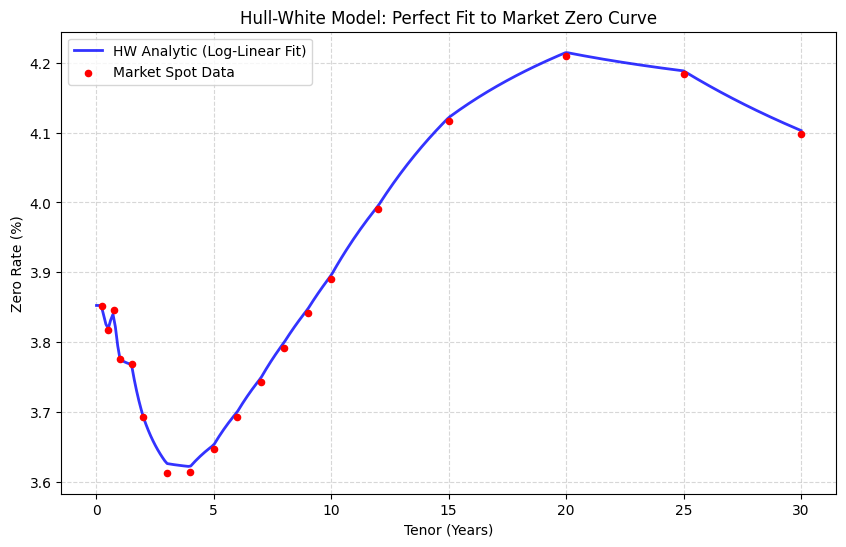

In [13]:
# --- HW 모델의 Zero Rate 계산 (t=0 기준) ---
import numpy as np
import matplotlib.pyplot as plt

def get_hw_model_zero_rate(t, T, r_t, a, sigma, curve_data):
    """
    t: 평가 시점 (오늘이면 0)
    T: 만기 시점
    r_t: t 시점의 단기 금리 (Short rate)
    a, sigma: HW 파라미터
    curve_data: 시장 데이터 (get_df, get_instantaneous_forward 함수 필요)
    """
    if T <= t: return get_instantaneous_forward(t, curve_data)

    tau = T - t
    B = (1 - np.exp(-a * tau)) / a

    P0_t = get_df(t, curve_data)
    P0_T = get_df(T, curve_data)
    f0_t = get_instantaneous_forward(t, curve_data)

    # ln A(t, T) 계산
    term_convexity = (sigma**2 / (4 * a)) * (1 - np.exp(-2 * a * t)) * (B**2)
    ln_A = np.log(P0_T / P0_t) + B * f0_t - term_convexity

    # P(t, T) = A(t, T) * exp(-B(t, T) * r_t)
    price = np.exp(ln_A - B * r_t)

    # Zero Rate = -ln(P(t, T)) / (T - t)
    return -np.log(price) / tau

# --- 시각화 실행 ---
tenor_grid = np.linspace(0.01, 30, 300)

# 오늘 시점의 short rate (r_0)는 시장의 즉시 선도금리 f(0,0)와 같습니다.
r0 = get_instantaneous_forward(0, SPOT_CURVE_DATA)

# 오늘(0)부터 만기(T)까지의 Zero Rate 계산
model_rates = [
    get_hw_model_zero_rate(0, T, r0, optimized_a, optimized_sigma, SPOT_CURVE_DATA) * 100
    for T in tenor_grid
]

plt.figure(figsize=(10, 6))
# 모델 곡선 (Log-linear에 의해 꺾인 선으로 나타남)
plt.plot(tenor_grid, model_rates, label="HW Analytic (Log-Linear Fit)", color='blue', linewidth=2, alpha=0.8)

# 실제 시장 데이터 포인트
market_tenors = [d['tenor'] for d in SPOT_CURVE_DATA]
market_rates = [d['zero_rate'] for d in SPOT_CURVE_DATA]
plt.scatter(market_tenors, market_rates, color='red', s=20, label="Market Spot Data", zorder=3)

plt.title("Hull-White Model: Perfect Fit to Market Zero Curve")
plt.xlabel("Tenor (Years)")
plt.ylabel("Zero Rate (%)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 8. HW Calbiration의 fitting 확인

**Hull-White 모델 검증: Analytic vs Monte Carlo (MC)**

이 코드는 최적화된 Hull-White 파라미터($a, \sigma$)를 사용하여 **분석적 해(Analytic Solution)**와 **수치적 시뮬레이션(Monte Carlo)** 간의 일치성을 검증


**Step 1. 분석적 가격 복원력 (Analytic Recovery)**

최적화 과정을 통해 얻은 파라미터가 시장의 스왑션 가격(Black Vol)을 얼마나 정확하게 재현하는지 확인합니다.

* **검증 지표**: 시장 가격(Market bps)과 모델 가격(HW Analytic bps) 사이의 **RMSE(Root Mean Square Error)**를 산출하여 캘리브레이션의 품질을 평가합니다.


**Step 2. 몬테카를로(MC) 시뮬레이션 및 주요 기법 (Tricks)**

단기 금리($r_t$)의 경로를 생성하여 스왑션 가격을 수치적으로 산출합니다. 이때 오차를 최소화하기 위해 다음 기법들이 사용되었습니다.

① Exact Transition (정확한 전이 샘플링)
* **Trick**: 오일러 근사(Euler approximation) 대신, $r_t$의 조건부 분포가 정규분포임을 이용하여 **분포의 모수(평균과 분산)를 정확하게 계산**해 다음 스텝을 샘플링합니다.
* **효과**: 시간 간격($dt$)에 따른 이산화 오차(Discretization Error)를 획기적으로 줄입니다.

② Trapezoidal Rule (사다리꼴 적분)
* **Trick**: 할인계수($e^{-\int r_s ds}$) 계산 시, 단순히 현재 시점의 금리($r_t$)를 쓰는 대신 **현재 값과 다음 스텝 값의 평균($\frac{r_t + r_{t+dt}}{2}$)**을 사용하여 적분값을 근사합니다.
* **효과**: 수치 적분의 정확도를 높여 시뮬레이션 가격의 편향(Bias)을 제거합니다.


**Step 3. Analytic vs Monte Carlo 비교 검증 (Consistency Check)**

이 프로세스의 최종 목적은 **"수식으로 구한 값과 시뮬레이션으로 구한 값이 소수점 단위까지 일치하는가?"**를 확인하는 것입니다.

* **일관성 검정**: 모든 캘리브레이션 데이터에 대해 두 방식의 차이(`Diff`)를 bps 단위로 계산합니다.
* **의의**:
    1.  **엔진 신뢰성**: 두 결과가 일치하면 MC 엔진이 수학적으로 올바르게 설계되었음을 증명합니다.
    2.  **확장성**: 검증된 MC 엔진은 나중에 분석적 해가 존재하지 않는 **Bermudan Swaption**이나 **Path-dependent** 상품 평가에 그대로 활용될 수 있습니다.

**해당 코드블록은 구현하셔야할 부분이 없습니다.**

**나오는 결과를 보고 swaption 가격을 복원하면 오차가 얼마나 나는지 확인하시고 문제가 있다면 위의 코드를 수정해주시면 될 것 같습니다.**

=== Hull-White Analytic Price Recovery ===
   Expiry  Tenor  Market_bps  HW_Analytic_bps  Error_bps
0     1.0    1.0       42.67           184.63     141.96
1     1.0    2.0       81.35           294.36     213.01
2     1.0    3.0      114.54           359.09     244.55
3     1.0    5.0      173.62           418.97     245.36
4     2.0    1.0       53.74           121.01      67.27
5     2.0    2.0      102.24           192.46      90.22
6     2.0    3.0      146.10           234.37      88.27
7     2.0    5.0      227.20           272.95      45.75
8     3.0    1.0       60.71            88.19      27.48
9     3.0    2.0      116.02           140.00      23.97

Total RMSE (bps): 124.7155
=== Hull-White Model Full Verification: Analytic vs Monte Carlo ===
Index | Exp/Ten    | Analytic(bps) | MC(bps)    | Diff(bps) 
-----------------------------------------------------------------
0     | 1.0Yx1.0Y  | 184.63        | 40.97      | -143.65   
1     | 1.0Yx2.0Y  | 294.36        | 64.44    

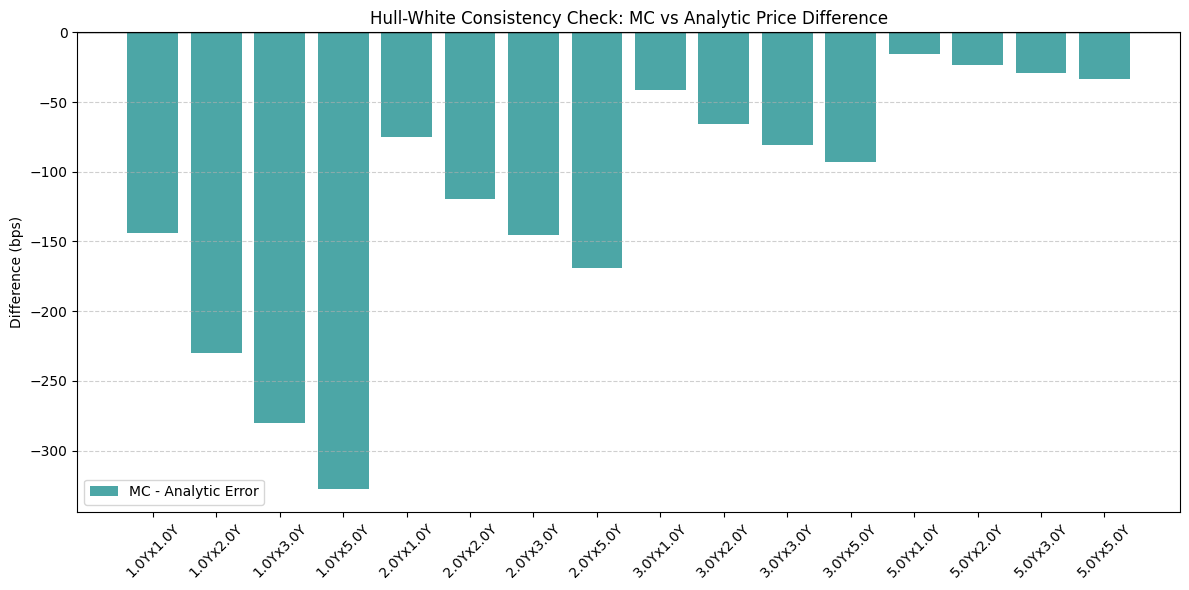

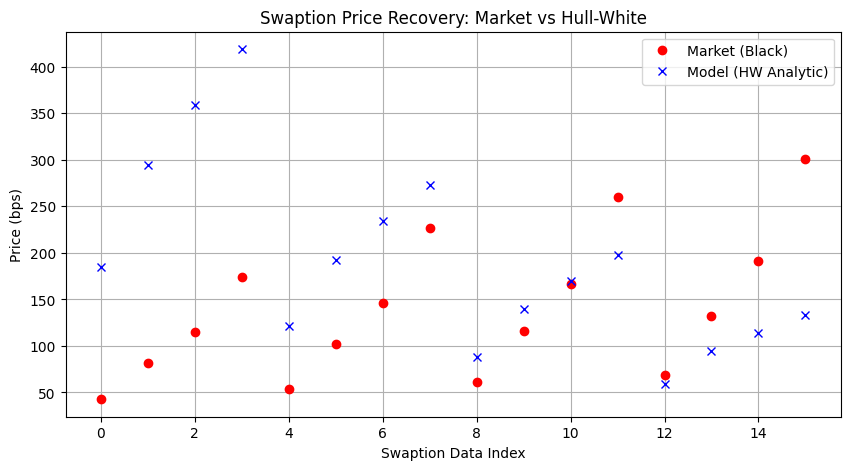

In [14]:
import pandas as pd

# -------------------------------------------------------------------------
# 1. 캘리브레이션 가격 복원력(Analytic Recovery) 확인
# -------------------------------------------------------------------------
def verify_analytic_recovery(calib_data, curve_data, a, sigma):
    recovery_results = []

    for d in calib_data:
        mkt_price_bps = d['Price_bps']
        # HW Analytic 가격 계산 (Jamshidian's Trick)
        model_price = hw_swaption_price(a, sigma, d['Expiry'], d['Tenor'],
                                        d['Forward_Swap_Rate'], curve_data)
        model_price_bps = model_price * 10000

        recovery_results.append({
            "Expiry": d['Expiry'],
            "Tenor": d['Tenor'],
            "Market_bps": round(mkt_price_bps, 2),
            "HW_Analytic_bps": round(model_price_bps, 2),
            "Error_bps": round(model_price_bps - mkt_price_bps, 2)
        })

    return pd.DataFrame(recovery_results)

recovery_df = verify_analytic_recovery(CALIBRATION_DATA, SPOT_CURVE_DATA, optimized_a, optimized_sigma)
print("=== Hull-White Analytic Price Recovery ===")
print(recovery_df.head(10))
print(f"\nTotal RMSE (bps): {np.sqrt((recovery_df['Error_bps']**2).mean()):.4f}")


# -------------------------------------------------------------------------
# 2. 헐-화이트 몬테카를로(MC) 시뮬레이션 엔진
# -------------------------------------------------------------------------
def hw_mc_swaption_price(a, sigma, expiry, tenor, strike, curve_data, n_paths=100000, n_steps=500):
    """
    Monte Carlo Simulation for Swaption using Exact Transition & Trapezoidal Rule
    """
    dt = expiry / n_steps
    times = np.linspace(0, expiry, n_steps + 1)

    # 초기화
    x = np.zeros(n_paths)
    integral_r = np.zeros(n_paths)

    # Exact Transition을 위한 상수 미리 계산
    phi = np.exp(-a * dt)
    # x(t)의 정확한 조건부 분산: (sigma^2 / 2a) * (1 - e^(-2a*dt))
    vol_x = np.sqrt((sigma**2 / (2 * a)) * (1 - np.exp(-2 * a * dt)))

    # 현재 시점(t=0)의 r_t 계산을 위한 준비
    alpha_0 = get_instantaneous_forward(0, curve_data) + (sigma**2 / (2 * a**2)) * (1 - np.exp(-a * 0))**2
    r_t = x + alpha_0 # 초기 x는 0

    for i in range(n_steps):
        t_next = times[i+1]

        # 1. Exact Transition: x(t) -> x(t+dt) 샘플링
        # 오일러 근사 대신 정확한 분포(Normal)에서 추출
        x_next = x * phi + vol_x * np.random.normal(0, 1, n_paths)

        # 2. 다음 시점의 r_(t+dt) 계산
        alpha_next = get_instantaneous_forward(t_next, curve_data) + (sigma**2 / (2 * a**2)) * (1 - np.exp(-a * t_next))**2
        r_next = x_next + alpha_next

        # 3. 사다리꼴 공식(Trapezoidal Rule)을 이용한 금리 적분 (할인계수용)
        # 이전 r_t와 현재 r_next의 평균값을 사용하여 적분 오차 최소화
        integral_r += 0.5 * (r_t + r_next) * dt

        # 다음 스텝을 위해 값 업데이트
        x = x_next
        r_t = r_next

    # 최종 시점의 r_T는 마지막 루프의 r_t와 동일
    r_T = r_t

    # --- 이후 Payoff 계산 로직은 동일 ---
    n_payments = int(tenor * 2)
    pay_times = [expiry + (i + 1) * 0.5 for i in range(n_payments)]
    cash_flows = [strike * 0.5 for _ in range(n_payments)]
    cash_flows[-1] += 1.0

    swap_values = np.zeros(n_paths)
    for i in range(n_payments):
        # 만기 시점 r_T에서의 ZCB 가격 (Analytic Bond Price 공식 활용)
        p_T_ti = hw_bond_price(r_T, expiry, pay_times[i], a, sigma, curve_data)
        swap_values += cash_flows[i] * p_T_ti

    # Payer Swaption Payoff: Max(1 - V_fixed_bond, 0)
    payoffs = np.maximum(1.0 - swap_values, 0)

    # Stochastic Discount Factor 적용 및 평균
    mc_price = np.mean(payoffs * np.exp(-integral_r))
    return mc_price

# -------------------------------------------------------------------------
# 모든 CALIBRATION_DATA에 대해 Analytic vs MC 가격 비교 수행
# -------------------------------------------------------------------------
verification_results = []

print("=== Hull-White Model Full Verification: Analytic vs Monte Carlo ===")
print(f"{'Index':<5} | {'Exp/Ten':<10} | {'Analytic(bps)':<13} | {'MC(bps)':<10} | {'Diff(bps)':<10}")
print("-" * 65)

# 전체 데이터를 순회 (데이터가 많을 경우 시간이 다소 소요될 수 있습니다)
for i, target in enumerate(CALIBRATION_DATA):
    exp = target['Expiry']
    ten = target['Tenor']
    k = target['Forward_Swap_Rate']
    mkt_p = target['Price_bps'] # 시장가 (Black)

    # 1. HW 분석적 가격 (Jamshidian's Trick)
    ana_p = hw_swaption_price(optimized_a, optimized_sigma, exp, ten, k, SPOT_CURVE_DATA) * 10000

    # 2. HW 몬테카를로 가격 (n_paths는 정확도를 위해 50,000회 유지)
    mc_p = hw_mc_swaption_price(optimized_a, optimized_sigma, exp, ten, k, SPOT_CURVE_DATA, n_paths=100000) * 10000

    # 3. 오차 계산 (MC와 Analytic 사이의 차이)
    diff = mc_p - ana_p

    res = {
        "Index": i,
        "Label": f"{exp}Yx{ten}Y",
        "Market_bps": round(mkt_p, 2),
        "Analytic_bps": round(ana_p, 2),
        "MC_bps": round(mc_p, 2),
        "MC_Analytic_Diff": round(diff, 2)
    }
    verification_results.append(res)

    print(f"{i:<5} | {res['Label']:<10} | {res['Analytic_bps']:<13.2f} | {res['MC_bps']:<10.2f} | {res['MC_Analytic_Diff']:<10.2f}")

# -------------------------------------------------------------------------
# 결과 분석 및 시각화
# -------------------------------------------------------------------------
v_df = pd.DataFrame(verification_results)

# 1. 통계치 출력
print("\n=== Verification Summary Statistics (Unit: bps) ===")
print(f"Mean Difference (MC - Analytic): {v_df['MC_Analytic_Diff'].mean():.4f}")
print(f"Max Difference: {v_df['MC_Analytic_Diff'].abs().max():.4f}")
print(f"RMSE (MC vs Analytic): {np.sqrt((v_df['MC_Analytic_Diff']**2).mean()):.4f}")

# 2. 결과 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# 데이터 인덱스별 차이(Diff) 플롯
plt.bar(v_df['Label'], v_df['MC_Analytic_Diff'], color='teal', alpha=0.7, label='MC - Analytic Error')
plt.axhline(0, color='black', linestyle='-', linewidth=1)
plt.title("Hull-White Consistency Check: MC vs Analytic Price Difference")
plt.ylabel("Difference (bps)")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 4. 결과 시각화 (복원력 그래프)
# -------------------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.plot(recovery_df.index, recovery_df['Market_bps'], 'ro', label='Market (Black)')
plt.plot(recovery_df.index, recovery_df['HW_Analytic_bps'], 'bx', label='Model (HW Analytic)')
plt.title("Swaption Price Recovery: Market vs Hull-White")
plt.ylabel("Price (bps)")
plt.xlabel("Swaption Data Index")
plt.legend()
plt.grid(True)
plt.show()